In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_parquet(Path("../data/processed/player_weeks_clean.parquet"))
df.shape

(37313, 161)

In [5]:
df.groupby("position")["fantasy_points_ppr"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
position,,,,,,,,
QB,4143.0,13.9,9.2,-5.7,6.8,13.8,20.2,51.9
RB,9764.0,7.8,8.0,-2.0,1.4,5.4,12.0,56.2
TE,7800.0,5.5,6.0,-2.0,1.4,3.5,8.4,45.6
WR,15606.0,7.4,7.8,-3.0,1.4,5.0,11.3,57.9


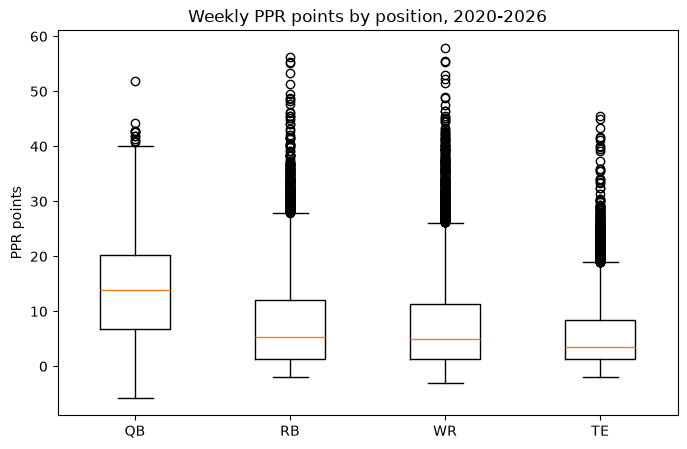

In [6]:
order = ["QB", "RB", "WR", "TE"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([df.loc[df["position"] == p, "fantasy_points_ppr"] for p in order],
           tick_labels=order)
ax.set_title("Weekly PPR points by position, 2020-2026")
ax.set_ylabel("PPR points")

fig.savefig("../reports/figures/ppr_by_position.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
df = df.sort_values(["player_id", "season", "week"])

# each player's points in his previous game of the same season
df["prev_ppr"] = df.groupby(["player_id", "season"])["fantasy_points_ppr"].shift(1)

pairs = df.dropna(subset=["prev_ppr"])     # week 1 has no previous game

corr = {pos: g["fantasy_points_ppr"].corr(g["prev_ppr"]) for pos, g in pairs.groupby("position")}
corr["ALL"] = pairs["fantasy_points_ppr"].corr(pairs["prev_ppr"])
pd.Series(corr).round(2)

QB     0.40
RB     0.50
TE     0.40
WR     0.44
ALL    0.50
dtype: float64

In [8]:
same_week_stats = ["receptions", "targets", "receiving_yards", "receiving_tds",
                   "carries", "rushing_yards", "rushing_tds",
                   "attempts", "completions", "passing_yards", "passing_tds",
                   "passing_interceptions", "offense_snaps", "offense_pct",
                   "fantasy_points"]

df[same_week_stats + ["fantasy_points_ppr"]].corr()["fantasy_points_ppr"].sort_values(ascending=False).round(2)

fantasy_points_ppr       1.00
fantasy_points           0.96
offense_snaps            0.63
offense_pct              0.62
receiving_yards          0.59
receptions               0.58
targets                  0.50
receiving_tds            0.50
rushing_tds              0.42
rushing_yards            0.42
passing_tds              0.41
passing_yards            0.38
carries                  0.37
completions              0.36
attempts                 0.34
passing_interceptions    0.13
Name: fantasy_points_ppr, dtype: float64